# Earthquke Damage Prediction

## Project objective
To analyze earthquake-affected building data and develop machine learning models to predict the damage grade of buildings

## Project Domain 
data scinence and machine learning 

## Target Variable 
damage _grade

# Damage categories
-1: Low Damage
-2: Medium Damage 
-3: Almost Complete Destruction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import sys

print("Python version:", sys.version)
print("Python location:", sys.executable)

import numpy

print("NumPy module type:", type(numpy))
print("NumPy module keys:", list(vars(numpy).keys())[:20])

Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python location: C:\AAAAAAAA\anaconda\python.exe
NumPy module type: <class 'module'>
NumPy module keys: ['__name__', '__doc__', '__package__', '__loader__', '__spec__', '__path__', '__file__', '__cached__', '__builtins__', 'version', '_expired_attrs_2_0', '__expired_attributes__', '_utils', '_globals', '_CopyMode', '_NoValue', '__version__', '__NUMPY_SETUP__', '_distributor_init', 'exceptions']


In [3]:
import numpy as np

numbers = np.array([10, 20, 30, 40, 50])

print("Array:", numbers)
print("Total:", np.sum(numbers))
print("Average:", np.mean(numbers))

Array: [10 20 30 40 50]
Total: 150
Average: 30.0


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas imported successfully!")

df = pd.DataFrame({
    'Age': [10, 20, 30],
    'Damage': [1, 2, 3]
})

print(df)

print("Matplotlib imported successfully!")
print("Seaborn imported successfully!")

Pandas imported successfully!
   Age  Damage
0   10       1
1   20       2
2   30       3
Matplotlib imported successfully!
Seaborn imported successfully!


In [5]:
import os

print("Current folder location:")
print(os.getcwd())

print("\nFiles available in this folder:")
print(os.listdir())

Current folder location:
C:\Users\Adil$

Files available in this folder:
['.anaconda', '.conda', '.continuum', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '3D Objects', 'AppData', 'Application Data', 'battery-report.html', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'Earthquake_Damage_Prediction.ipynb', 'Favorites', 'Links', 'Local Settings', 'Microsoft', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TM.blf', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Pictures', 'PRCP-1015-EquakeDamagePred', 'PRCP-1015-EquakeDamagePred.pdf.docx', 'PRCP-1015-EquakeDamagePred.zip', 'PrintHood', 'Recent', 'Saved Games', 'Searches', 'SendTo', 'Start Menu', 'Templates', 'train_labels.csv', 'train_values.csv', 'V

In [6]:
import pandas as pd

# Load building features
train_values = pd.read_csv("train_values.csv")

# Load damage labels
train_labels = pd.read_csv("train_labels.csv")

print("Both datasets loaded successfully!")

print("Train Values Shape:", train_values.shape)
print("Train Labels Shape:", train_labels.shape)

Both datasets loaded successfully!
Train Values Shape: (260601, 39)
Train Labels Shape: (260601, 2)


In [7]:
# Display first 5 rows of building data
train_values.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,0


In [8]:
# Dataset information
print("BUILDING DATA INFORMATION")
train_values.info()

# Check missing values
print("\nMISSING VALUES")
print(train_values.isnull().sum().sum())

# Damage grade distribution
print("\nDAMAGE GRADE DISTRIBUTION")
print(train_labels['damage_grade'].value_counts())

BUILDING DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 39 columns):
 #   Column                                  Non-Null Count   Dtype 
---  ------                                  --------------   ----- 
 0   building_id                             260601 non-null  int64 
 1   geo_level_1_id                          260601 non-null  int64 
 2   geo_level_2_id                          260601 non-null  int64 
 3   geo_level_3_id                          260601 non-null  int64 
 4   count_floors_pre_eq                     260601 non-null  int64 
 5   age                                     260601 non-null  int64 
 6   area_percentage                         260601 non-null  int64 
 7   height_percentage                       260601 non-null  int64 
 8   land_surface_condition                  260601 non-null  object
 9   foundation_type                         260601 non-null  object
 10  roof_type                     

In [9]:
# Display first 5 rows of the dataset
display(train_values.head())

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,0


In [10]:
# Merge building features and damage labels

df = pd.merge(train_values, train_labels, on="building_id")

# Display merged dataset shape
print("Merged Dataset Shape:", df.shape)

# Display first 5 rows
display(df.head())

Merged Dataset Shape: (260601, 40)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,3


In [11]:
# Check duplicate rows
print("Total Duplicate Rows:", df.duplicated().sum())

# Check duplicate building IDs
print("Duplicate Building IDs:", df["building_id"].duplicated().sum())

Total Duplicate Rows: 0
Duplicate Building IDs: 0


In [12]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values[missing_values > 0])

# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values in Each Column:
Series([], dtype: int64)

Total Missing Values: 0


In [13]:
# Count each damage grade
damage_counts = df["damage_grade"].value_counts().sort_index()

print("Damage Grade Distribution:")
print(damage_counts)

# Calculate percentage
damage_percentage = df["damage_grade"].value_counts(
    normalize=True
).sort_index() * 100

print("\nDamage Grade Percentage:")
print(damage_percentage)

Damage Grade Distribution:
damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64

Damage Grade Percentage:
damage_grade
1     9.640792
2    56.891186
3    33.468022
Name: proportion, dtype: float64


In [14]:
# Identify numerical columns
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=['object']
).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

print("\nTotal Numerical Columns:", len(numerical_columns))
print("Total Categorical Columns:", len(categorical_columns))

Numerical Columns:
['building_id', 'geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_secondary_use_use_police', 'has_secondary_use_other', 'damage_grade']

Categorical Columns:
['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor

Numerical Columns      32
Categorical Columns     8
dtype: int64


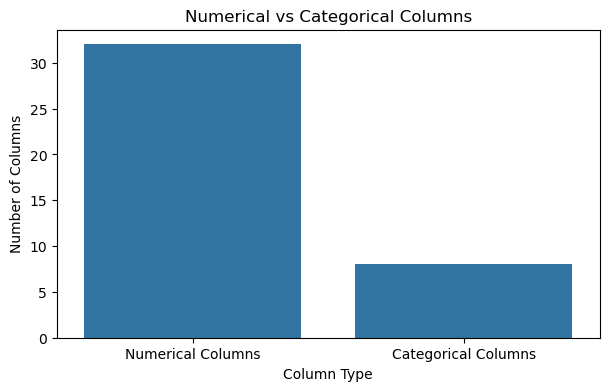

In [15]:
# Count numerical and categorical columns
column_types = pd.Series({
    "Numerical Columns": len(numerical_columns),
    "Categorical Columns": len(categorical_columns)
})

# Display counts
print(column_types)

# Create bar chart
plt.figure(figsize=(7, 4))
sns.barplot(x=column_types.index, y=column_types.values)

plt.title("Numerical vs Categorical Columns")
plt.xlabel("Column Type")
plt.ylabel("Number of Columns")
plt.show()

In [16]:
# Select numerical columns for statistical analysis
numeric_data = df.select_dtypes(include=['int64', 'float64'])

# Remove building_id and damage_grade
numeric_data = numeric_data.drop(
    columns=['building_id', 'damage_grade'],
    errors='ignore'
)

# Display statistical summary
numeric_data.describe()

,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
count,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,...,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000
mean,13.900353,701.074685,6257.876148,2.129723,26.535029,8.018051,5.434365,0.088645,0.761935,0.034332,...,0.064378,0.033626,0.008101,0.000940,0.000361,0.001071,0.000188,0.000146,0.000088,0.005119
std,8.033617,412.710734,3646.369645,0.727665,73.565937,4.392231,1.918418,0.284231,0.425900,0.182081,...,0.245426,0.180265,0.089638,0.030647,0.018989,0.032703,0.013711,0.012075,0.009394,0.071364
min,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7.000000,350.000000,3073.000000,2.000000,10.000000,5.000000,4.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,12.000000,702.000000,6270.000000,2.000000,15.000000,7.000000,5.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,21.000000,1050.000000,9412.000000,2.000000,30.000000,9.000000,6.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,30.000000,1427.000000,12567.000000,9.000000,995.000000,100.000000,32.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


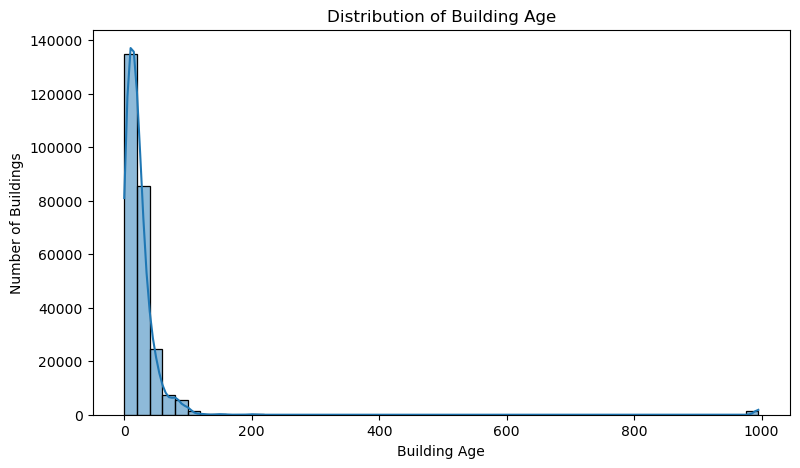

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="age", bins=50, kde=True)

plt.title("Distribution of Building Age")
plt.xlabel("Building Age")
plt.ylabel("Number of Buildings")

plt.show()

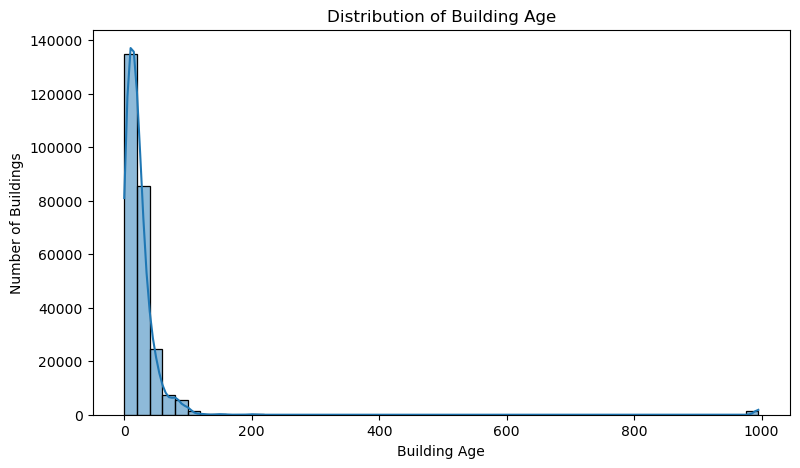

In [18]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="age", bins=50, kde=True)

plt.title("Distribution of Building Age")
plt.xlabel("Building Age")
plt.ylabel("Number of Buildings")

plt.show()

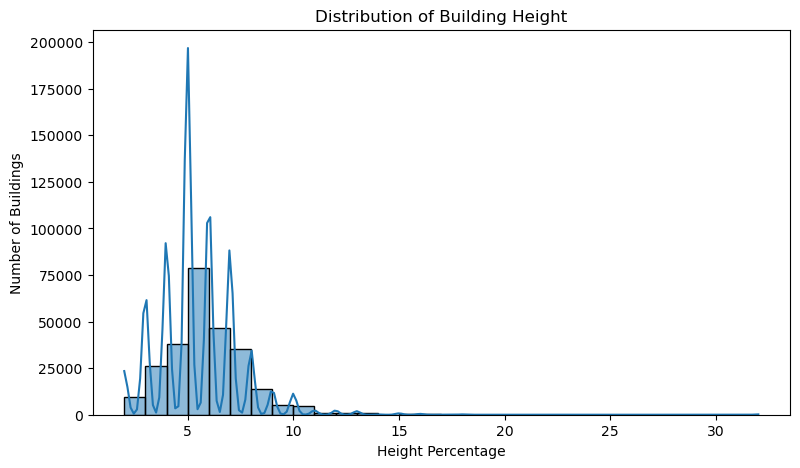

In [19]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="height_percentage", bins=30, kde=True)

plt.title("Distribution of Building Height")
plt.xlabel("Height Percentage")
plt.ylabel("Number of Buildings")

plt.show()

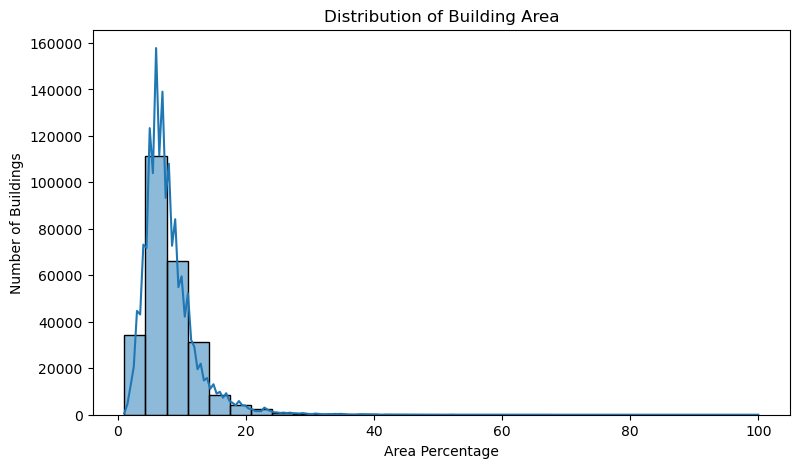

In [20]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="area_percentage", bins=30, kde=True)

plt.title("Distribution of Building Area")
plt.xlabel("Area Percentage")
plt.ylabel("Number of Buildings")

plt.show()

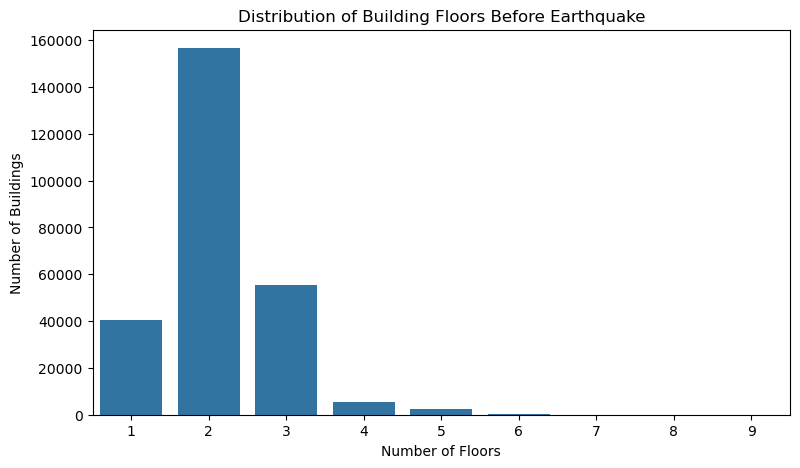

In [21]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="count_floors_pre_eq"
)

plt.title("Distribution of Building Floors Before Earthquake")
plt.xlabel("Number of Floors")
plt.ylabel("Number of Buildings")

plt.show()

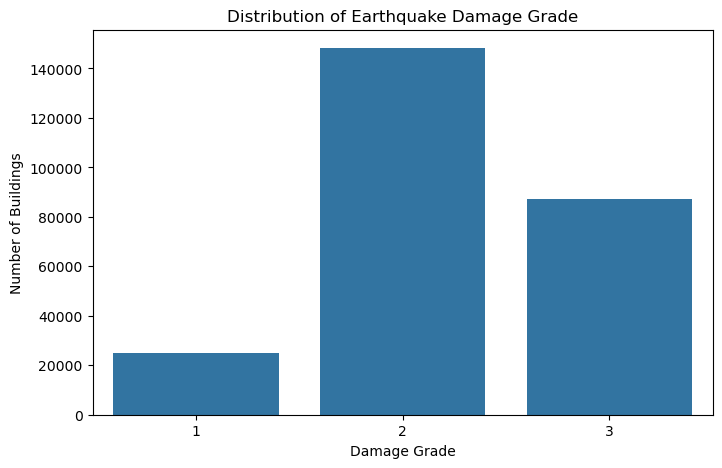

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="damage_grade"
)

plt.title("Distribution of Earthquake Damage Grade")
plt.xlabel("Damage Grade")
plt.ylabel("Number of Buildings")

plt.show()

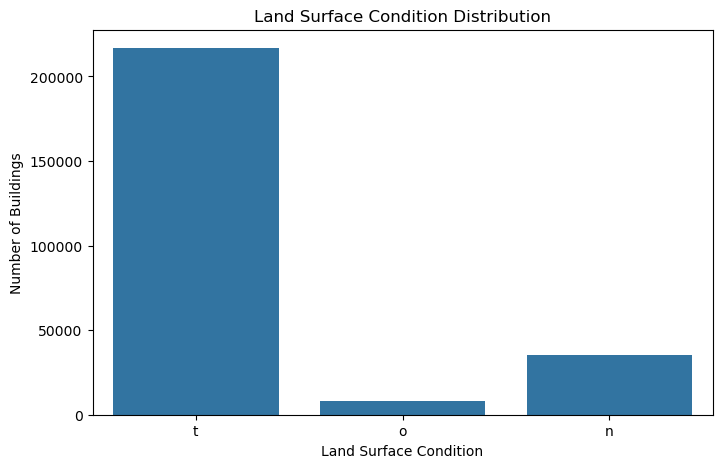

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="land_surface_condition"
)

plt.title("Land Surface Condition Distribution")
plt.xlabel("Land Surface Condition")
plt.ylabel("Number of Buildings")

plt.show()

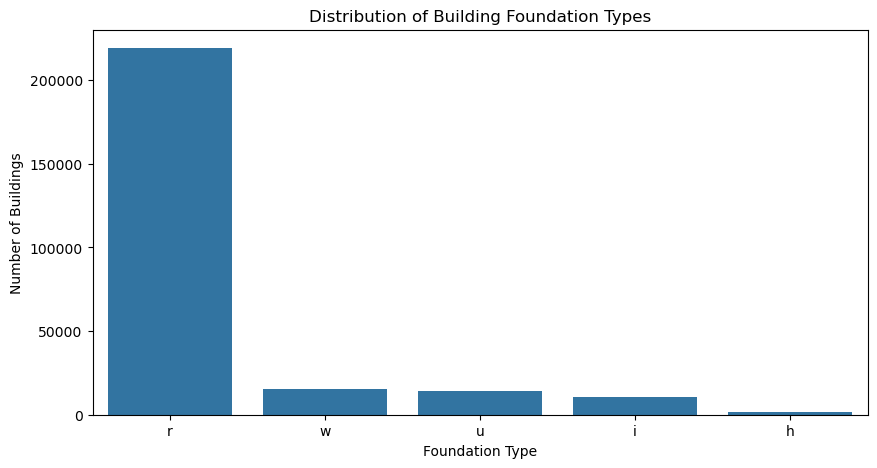

In [24]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="foundation_type",
    order=df["foundation_type"].value_counts().index
)

plt.title("Distribution of Building Foundation Types")
plt.xlabel("Foundation Type")
plt.ylabel("Number of Buildings")

plt.show()

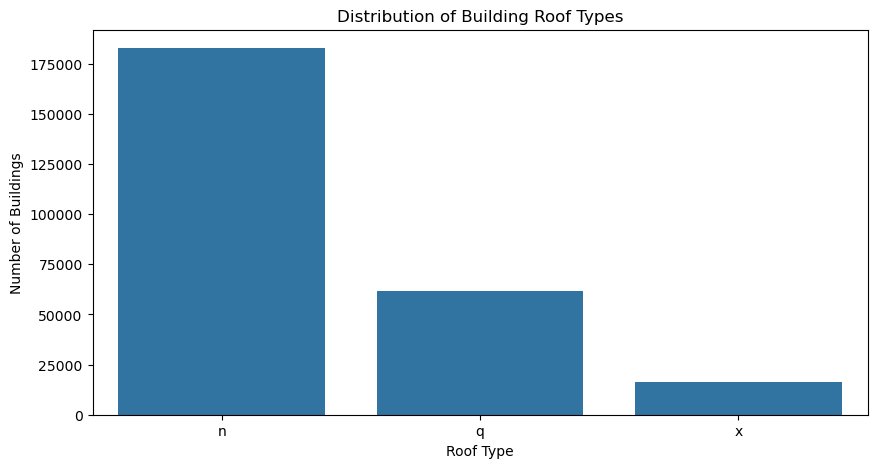

In [25]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="roof_type",
    order=df["roof_type"].value_counts().index
)

plt.title("Distribution of Building Roof Types")
plt.xlabel("Roof Type")
plt.ylabel("Number of Buildings")

plt.show()

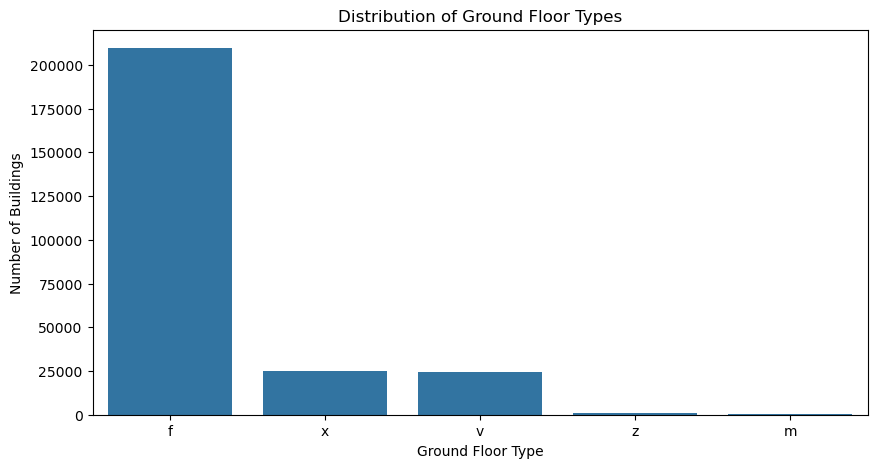

In [26]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="ground_floor_type",
    order=df["ground_floor_type"].value_counts().index
)

plt.title("Distribution of Ground Floor Types")
plt.xlabel("Ground Floor Type")
plt.ylabel("Number of Buildings")

plt.show()

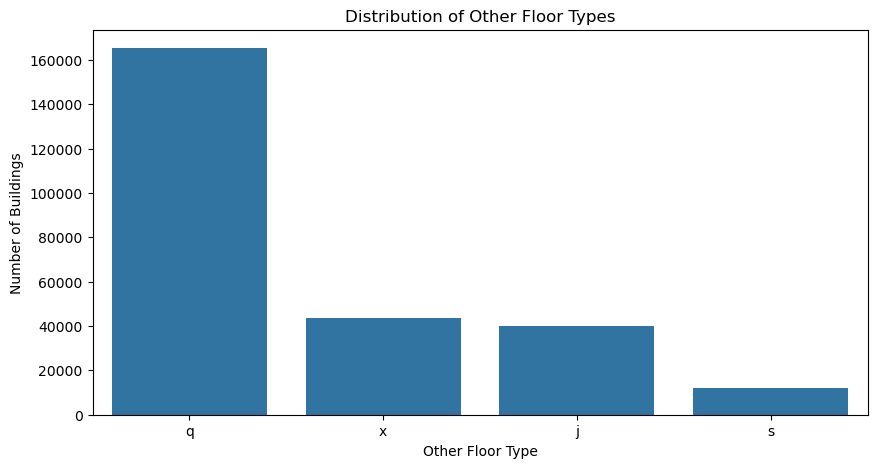

In [27]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="other_floor_type",
    order=df["other_floor_type"].value_counts().index
)

plt.title("Distribution of Other Floor Types")
plt.xlabel("Other Floor Type")
plt.ylabel("Number of Buildings")

plt.show()

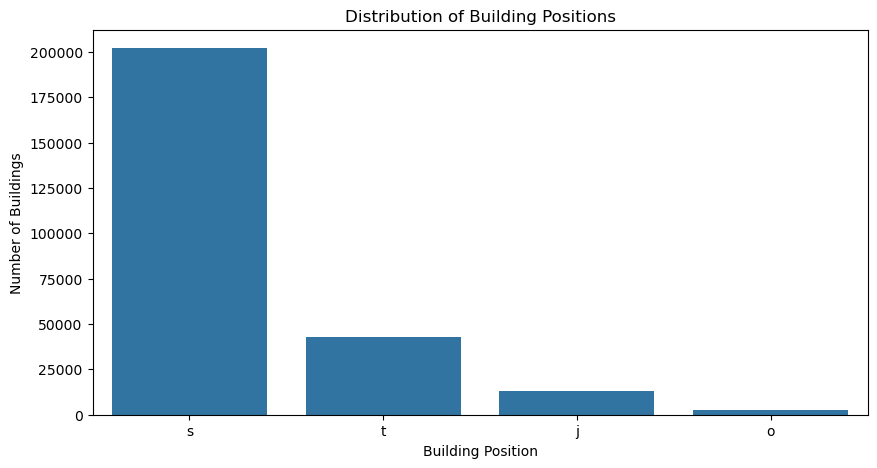

In [28]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="position",
    order=df["position"].value_counts().index
)

plt.title("Distribution of Building Positions")
plt.xlabel("Building Position")
plt.ylabel("Number of Buildings")

plt.show()

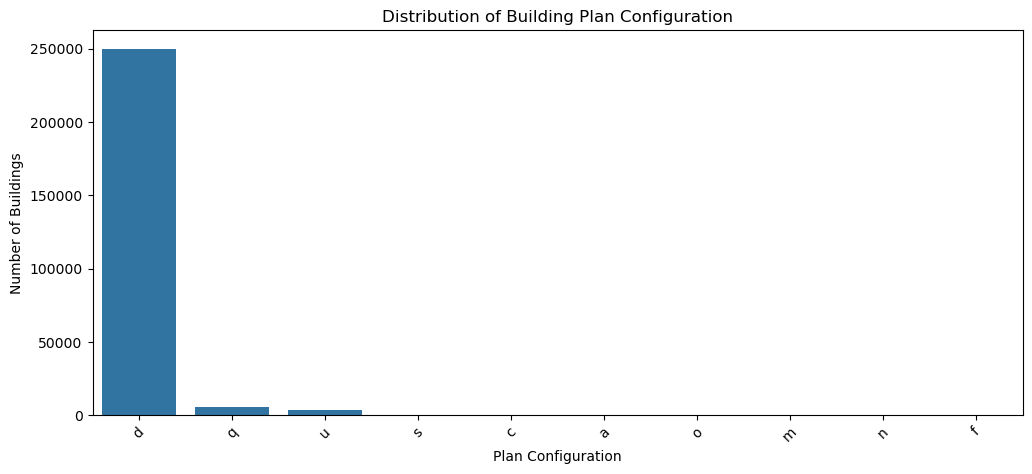

In [29]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="plan_configuration",
    order=df["plan_configuration"].value_counts().index
)

plt.title("Distribution of Building Plan Configuration")
plt.xlabel("Plan Configuration")
plt.ylabel("Number of Buildings")

plt.xticks(rotation=45)
plt.show()

Superstructure Material Usage:
has_superstructure_mud_mortar_stone       198561
has_superstructure_timber                  66450
has_superstructure_adobe_mud               23101
has_superstructure_bamboo                  22154
has_superstructure_cement_mortar_brick     19615
has_superstructure_mud_mortar_brick        17761
has_superstructure_rc_non_engineered       11099
has_superstructure_stone_flag               8947
has_superstructure_cement_mortar_stone      4752
has_superstructure_rc_engineered            4133
has_superstructure_other                    3905
dtype: int64


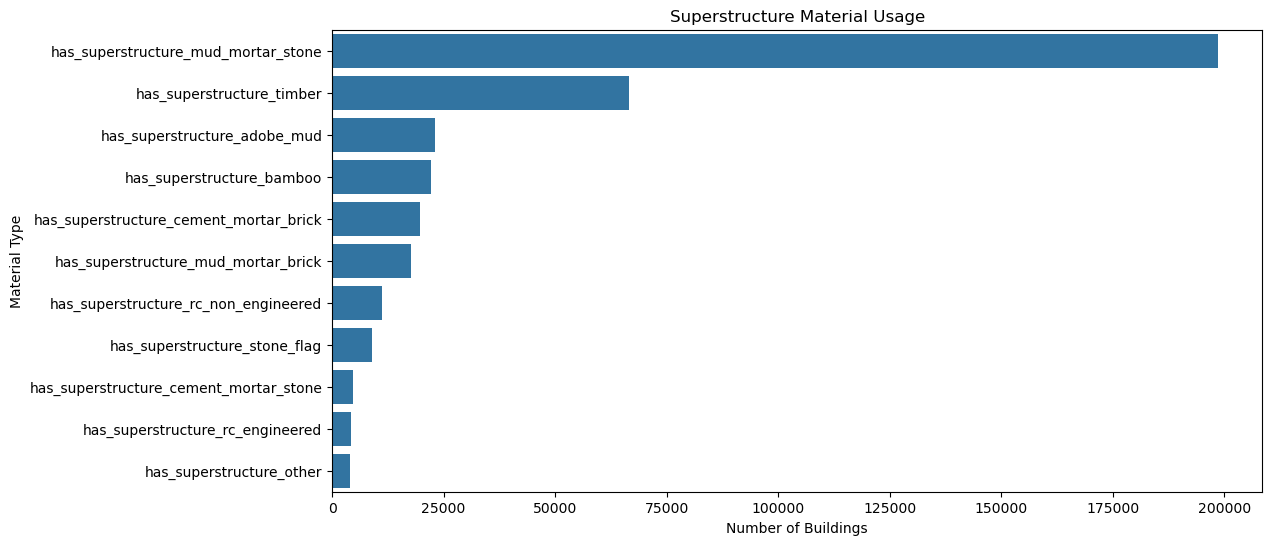

In [30]:
# Select superstructure material columns
material_columns = [
    col for col in df.columns
    if col.startswith("has_superstructure_")
]

# Calculate material usage count
material_counts = df[material_columns].sum().sort_values(
    ascending=False
)

# Display material counts
print("Superstructure Material Usage:")
print(material_counts)

# Visualize material usage
plt.figure(figsize=(12, 6))

sns.barplot(
    x=material_counts.values,
    y=material_counts.index
)

plt.title("Superstructure Material Usage")
plt.xlabel("Number of Buildings")
plt.ylabel("Material Type")

plt.show()

Building Secondary Use Counts:
has_secondary_use                29156
has_secondary_use_agriculture    16777
has_secondary_use_hotel           8763
has_secondary_use_rental          2111
has_secondary_use_other           1334
has_secondary_use_industry         279
has_secondary_use_institution      245
has_secondary_use_school            94
has_secondary_use_health_post       49
has_secondary_use_gov_office        38
has_secondary_use_use_police        23
dtype: int64


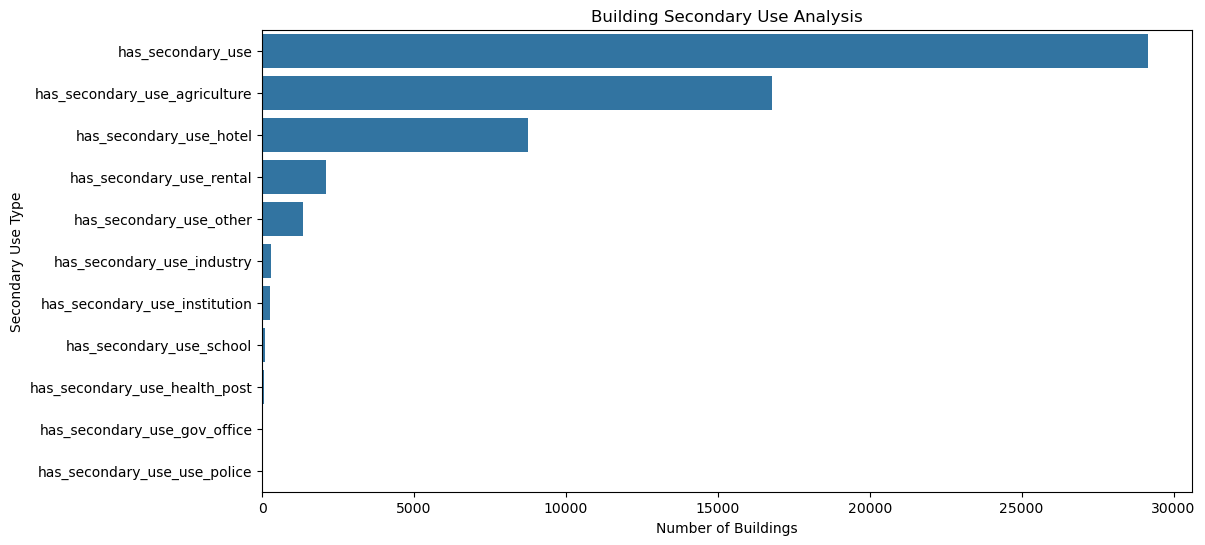

In [31]:
# Select secondary use columns
secondary_columns = [
    col for col in df.columns
    if col.startswith("has_secondary_use")
]

# Calculate secondary use counts
secondary_counts = df[secondary_columns].sum().sort_values(
    ascending=False
)

# Display results
print("Building Secondary Use Counts:")
print(secondary_counts)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=secondary_counts.values,
    y=secondary_counts.index
)

plt.title("Building Secondary Use Analysis")
plt.xlabel("Number of Buildings")
plt.ylabel("Secondary Use Type")

plt.show()

Legal Ownership Status:
legal_ownership_status
v    250939
a      5512
w      2677
r      1473
Name: count, dtype: int64


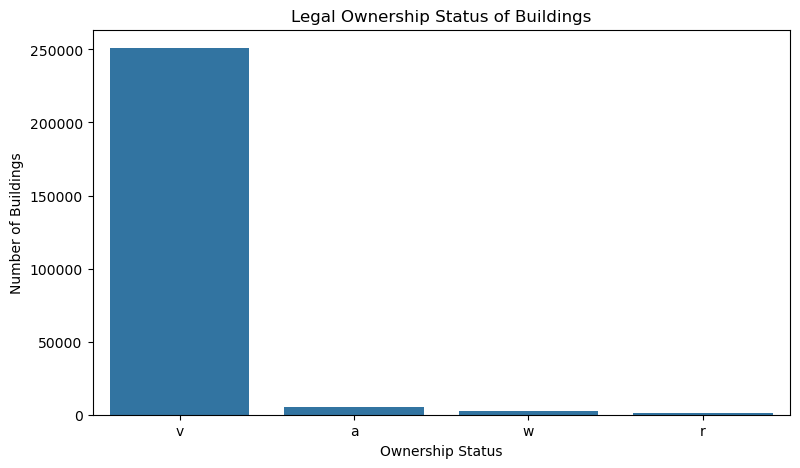

In [32]:
# Count buildings by legal ownership status
ownership_counts = df["legal_ownership_status"].value_counts()

# Display counts
print("Legal Ownership Status:")
print(ownership_counts)

# Create bar chart
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="legal_ownership_status",
    order=ownership_counts.index
)

plt.title("Legal Ownership Status of Buildings")
plt.xlabel("Ownership Status")
plt.ylabel("Number of Buildings")

plt.show()

Legal Ownership Status:
legal_ownership_status
v    250939
a      5512
w      2677
r      1473
Name: count, dtype: int64


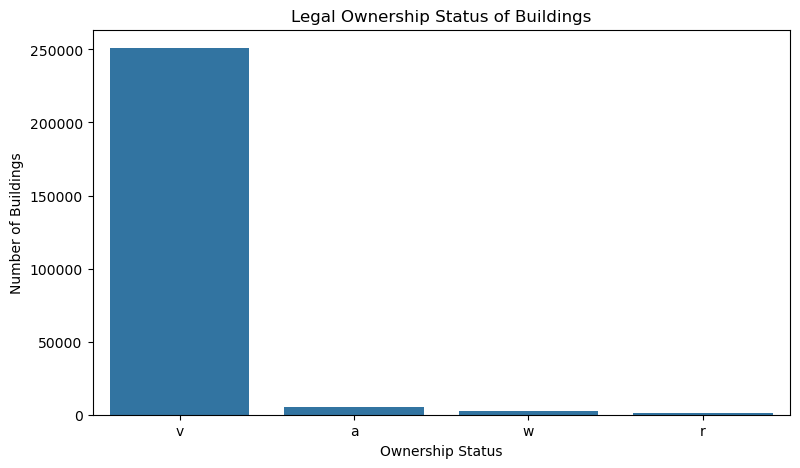

In [33]:
# Count buildings by legal ownership status
ownership_counts = df["legal_ownership_status"].value_counts()

# Display counts
print("Legal Ownership Status:")
print(ownership_counts)

# Create bar chart
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="legal_ownership_status",
    order=ownership_counts.index
)

plt.title("Legal Ownership Status of Buildings")
plt.xlabel("Ownership Status")
plt.ylabel("Number of Buildings")

plt.show()

Correlation with Damage Grade:
damage_grade                              1.000000
has_superstructure_mud_mortar_stone       0.291325
count_floors_pre_eq                       0.122308
has_superstructure_stone_flag             0.066039
count_families                            0.056151
has_superstructure_adobe_mud              0.055314
height_percentage                         0.048130
geo_level_2_id                            0.043161
age                                       0.029273
has_superstructure_mud_mortar_brick       0.014561
has_secondary_use_agriculture             0.011309
geo_level_3_id                            0.007932
building_id                               0.001063
has_secondary_use_use_police             -0.001656
has_secondary_use_health_post            -0.008543
has_secondary_use_gov_office             -0.009378
has_secondary_use_industry               -0.011024
has_secondary_use_school                 -0.011692
has_secondary_use_other                  -0.016334


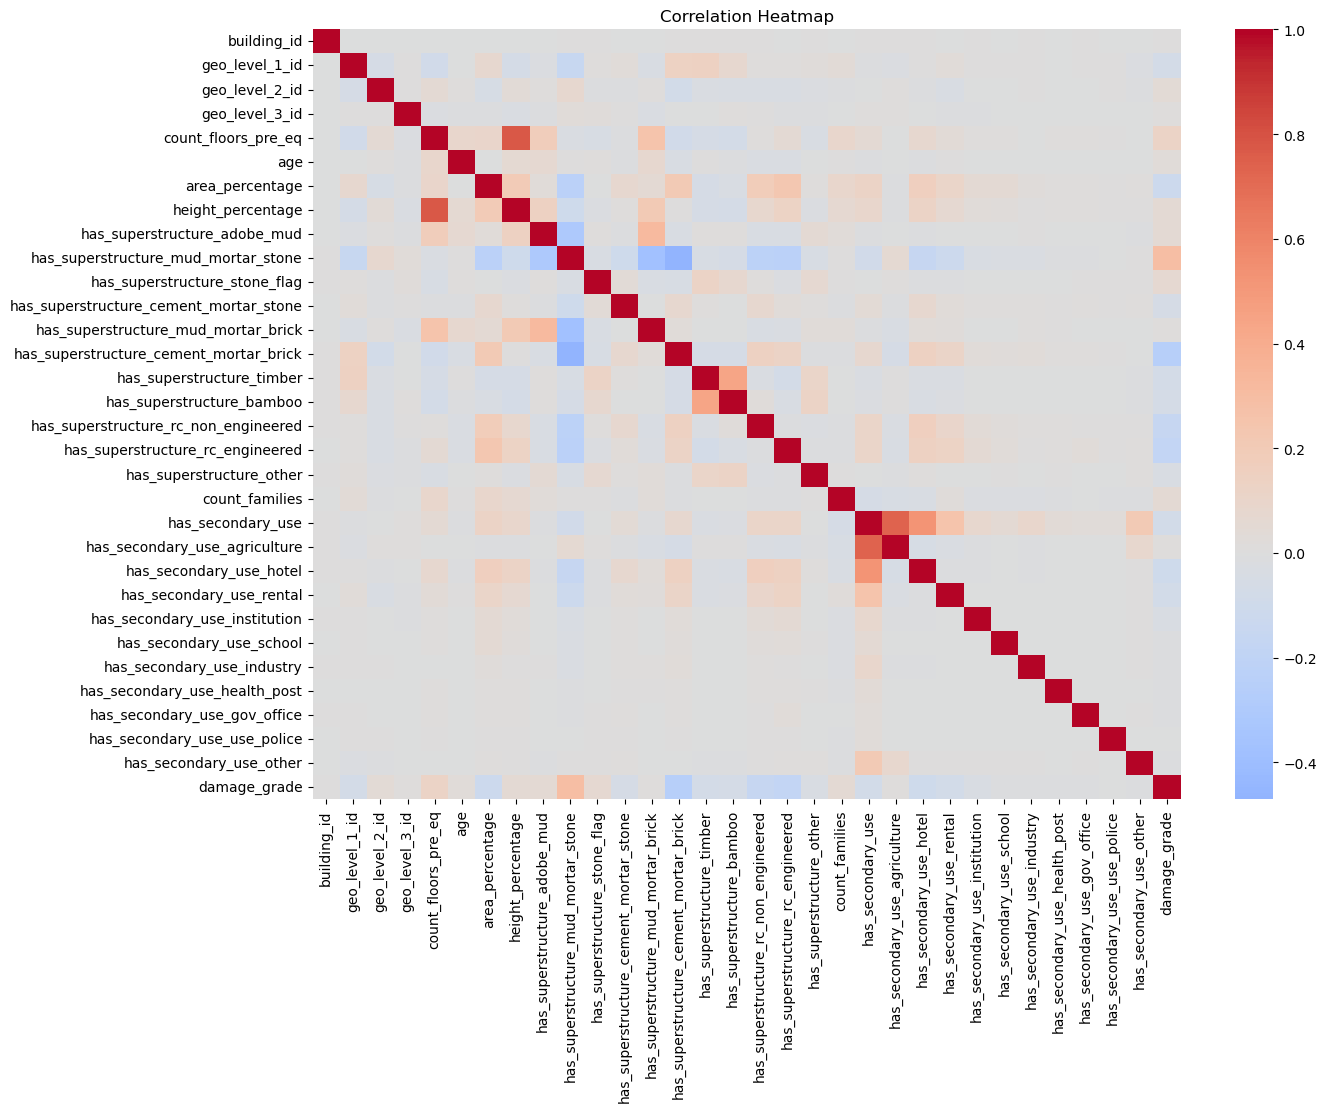

In [34]:
# Select numerical columns
numeric_data = df.select_dtypes(include=["int64", "float64"])

# Calculate correlation
correlation = numeric_data.corr()

# Display correlation with damage grade
print("Correlation with Damage Grade:")
print(
    correlation["damage_grade"]
    .sort_values(ascending=False)
)

# Create correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.show()

In [35]:
# Find features most positively and negatively correlated with damage_grade
damage_correlation = correlation["damage_grade"].drop(
    ["damage_grade", "building_id"],
    errors="ignore"
)

print("Top 5 Positive Correlations:")
print(damage_correlation.sort_values(ascending=False).head(5))

print("\nTop 5 Negative Correlations:")
print(damage_correlation.sort_values().head(5))

# Display damage grade distribution
print("\nDamage Grade Distribution:")
print(df["damage_grade"].value_counts().sort_index())

Top 5 Positive Correlations:
has_superstructure_mud_mortar_stone    0.291325
count_floors_pre_eq                    0.122308
has_superstructure_stone_flag          0.066039
count_families                         0.056151
has_superstructure_adobe_mud           0.055314
Name: damage_grade, dtype: float64

Top 5 Negative Correlations:
has_superstructure_cement_mortar_brick   -0.254131
has_superstructure_rc_engineered         -0.179014
has_superstructure_rc_non_engineered     -0.158145
area_percentage                          -0.125221
has_secondary_use_hotel                  -0.097942
Name: damage_grade, dtype: float64

Damage Grade Distribution:
damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64


In [36]:
# Separate input features (X)
X = df.drop(
    columns=["building_id", "damage_grade"]
)

# Separate target variable (y)
y = df["damage_grade"]

# Display shapes
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Display first five rows
print("\nFeatures Preview:")
display(X.head())

print("\nTarget Preview:")
display(y.head())

Features Shape: (260601, 38)
Target Shape: (260601,)

Features Preview:


,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,6,487,12198,2,30,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,0
1,8,900,2812,2,10,8,7,o,r,n,...,0,0,0,0,0,0,0,0,0,0
2,21,363,8973,2,10,5,5,t,r,n,...,0,0,0,0,0,0,0,0,0,0
3,22,418,10694,2,10,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,0
4,11,131,1488,3,30,8,9,t,r,n,...,0,0,0,0,0,0,0,0,0,0



Target Preview:


0    3
1    2
2    3
3    2
4    3
Name: damage_grade, dtype: int64

In [37]:
# Identify numerical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

# Identify categorical columns
categorical_features = X.select_dtypes(
    include=["object"]
).columns

# Display results
print("Total Numerical Features:", len(numerical_features))
print("Total Categorical Features:", len(categorical_features))

print("\nNumerical Columns:")
print(list(numerical_features))

print("\nCategorical Columns:")
print(list(categorical_features))

Total Numerical Features: 30
Total Categorical Features: 8

Numerical Columns:
['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_secondary_use_use_police', 'has_secondary_use_other']

Categorical Columns:
['land_surface_condition', 'foundation_type

In [38]:
# Count unique categories in each categorical feature
for col in categorical_features:
    print(col, ":", X[col].nunique(), "unique categories")

land_surface_condition : 3 unique categories
foundation_type : 5 unique categories
roof_type : 3 unique categories
ground_floor_type : 5 unique categories
other_floor_type : 4 unique categories
position : 4 unique categories
plan_configuration : 10 unique categories
legal_ownership_status : 4 unique categories


In [39]:
# Apply One-Hot Encoding to categorical features
X_encoded = pd.get_dummies(
    X,
    columns=list(categorical_features),
    dtype=int
)

# Display results
print("Original Features Shape:", X.shape)
print("Encoded Features Shape:", X_encoded.shape)

print("\nEncoded Data Preview:")
display(X_encoded.head())

Original Features Shape: (260601, 38)
Encoded Features Shape: (260601, 68)

Encoded Data Preview:


,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,...,plan_configuration_m,plan_configuration_n,plan_configuration_o,plan_configuration_q,plan_configuration_s,plan_configuration_u,legal_ownership_status_a,legal_ownership_status_r,legal_ownership_status_v,legal_ownership_status_w
0,6,487,12198,2,30,6,5,1,1,0,...,0,0,0,0,0,0,0,0,1,0
1,8,900,2812,2,10,8,7,0,1,0,...,0,0,0,0,0,0,0,0,1,0
2,21,363,8973,2,10,5,5,0,1,0,...,0,0,0,0,0,0,0,0,1,0
3,22,418,10694,2,10,6,5,0,1,0,...,0,0,0,0,0,0,0,0,1,0
4,11,131,1488,3,30,8,9,1,0,0,...,0,0,0,0,0,0,0,0,1,0


In [40]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display shapes
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (208480, 68)
X_test Shape: (52121, 68)
y_train Shape: (208480,)
y_test Shape: (52121,)


In [41]:
# Check training and testing data
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Check missing values
print("Missing Values in Training Data:", X_train.isnull().sum().sum())
print("Missing Values in Testing Data:", X_test.isnull().sum().sum())

# Check target classes
print("\nTraining Target Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Target Distribution:")
print(y_test.value_counts().sort_index())

Training Data Shape: (208480, 68)
Testing Data Shape: (52121, 68)
Missing Values in Training Data: 0
Missing Values in Testing Data: 0

Training Target Distribution:
damage_grade
1     20099
2    118607
3     69774
Name: count, dtype: int64

Testing Target Distribution:
damage_grade
1     5025
2    29652
3    17444
Name: count, dtype: int64


In [42]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


In [43]:
# Predict damage grades using Random Forest
y_pred = rf_model.predict(X_test)

# Display first 10 predictions
print("First 10 Actual Damage Grades:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Damage Grades:")
print(y_pred[:10])

First 10 Actual Damage Grades:
[3 2 2 2 3 3 3 2 2 2]

First 10 Predicted Damage Grades:
[2 2 1 2 3 2 3 2 3 2]


In [44]:
from sklearn.metrics import accuracy_score

# Calculate model accuracy
rf_accuracy = accuracy_score(y_test, y_pred)

# Display accuracy
print("Random Forest Accuracy:", rf_accuracy)

print("Accuracy Percentage:", rf_accuracy * 100, "%")

Random Forest Accuracy: 0.7160453559985418
Accuracy Percentage: 71.60453559985417 %


In [45]:
from sklearn.metrics import classification_report

# Generate classification report
rf_report = classification_report(
    y_test,
    y_pred,
    target_names=[
        "Grade 1 - Low Damage",
        "Grade 2 - Medium Damage",
        "Grade 3 - Severe Damage"
    ]
)

print("Random Forest Classification Report:")
print(rf_report)

Random Forest Classification Report:
                         precision    recall  f1-score   support

   Grade 1 - Low Damage       0.64      0.48      0.55      5025
Grade 2 - Medium Damage       0.72      0.82      0.77     29652
Grade 3 - Severe Damage       0.72      0.60      0.65     17444

               accuracy                           0.72     52121
              macro avg       0.69      0.64      0.66     52121
           weighted avg       0.71      0.72      0.71     52121



Confusion Matrix:
[[ 2427  2493   105]
 [ 1230 24405  4017]
 [  130  6825 10489]]


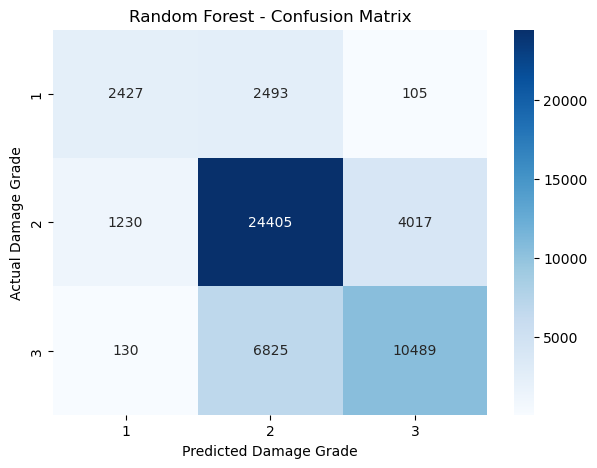

In [46]:
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3],
    yticklabels=[1, 2, 3]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Damage Grade")
plt.ylabel("Actual Damage Grade")

plt.show()

In [47]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=20,
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree Model Training Completed!")

Decision Tree Model Training Completed!


In [48]:
from sklearn.metrics import accuracy_score, classification_report

# Predict using Decision Tree
dt_pred = dt_model.predict(X_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print("Decision Tree Accuracy Percentage:", dt_accuracy * 100, "%")

# Classification report
print("\nDecision Tree Classification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 0.6976842347614205
Decision Tree Accuracy Percentage: 69.76842347614205 %

Decision Tree Classification Report:
              precision    recall  f1-score   support

           1       0.55      0.47      0.51      5025
           2       0.72      0.78      0.75     29652
           3       0.69      0.61      0.65     17444

    accuracy                           0.70     52121
   macro avg       0.65      0.62      0.64     52121
weighted avg       0.69      0.70      0.69     52121



Model Performance Comparison:


,Model,Accuracy
0,Random Forest,0.716045
1,Decision Tree,0.697684


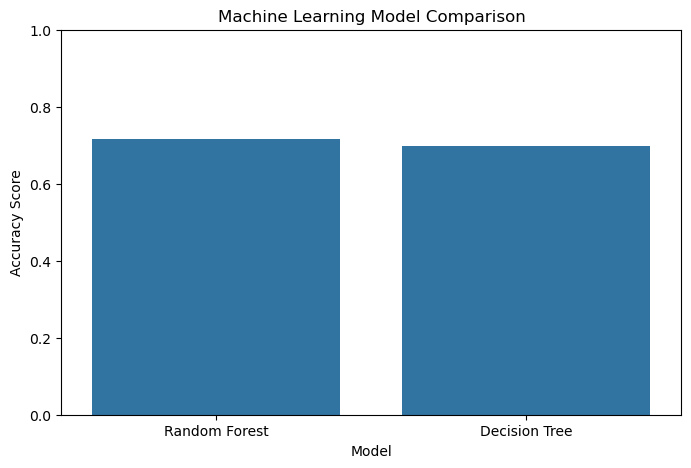

In [49]:
# Create model comparison table
model_comparison = pd.DataFrame({
    "Model": ["Random Forest", "Decision Tree"],
    "Accuracy": [rf_accuracy, dt_accuracy]
})

# Display comparison
print("Model Performance Comparison:")
display(model_comparison)

# Visualize model accuracy
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Accuracy Score")
plt.ylim(0, 1)

plt.show()

In [50]:
from sklearn.metrics import accuracy_score, f1_score

# Calculate evaluation metrics
rf_f1 = f1_score(y_test, y_pred, average="macro")
dt_f1 = f1_score(y_test, dt_pred, average="macro")

# Create final comparison table
final_comparison = pd.DataFrame({
    "Model": ["Random Forest", "Decision Tree"],
    "Accuracy": [rf_accuracy, dt_accuracy],
    "Macro F1-Score": [rf_f1, dt_f1]
})

print("Final Model Comparison:")
display(final_comparison)

# Select model based on Macro F1-score
if rf_f1 >= dt_f1:
    best_model = rf_model
    best_model_name = "Random Forest"
else:
    best_model = dt_model
    best_model_name = "Decision Tree"

print("Best Model:", best_model_name)

Final Model Comparison:


,Model,Accuracy,Macro F1-Score
0,Random Forest,0.716045,0.658485
1,Decision Tree,0.697684,0.636670


Best Model: Random Forest


## Challenges Faced Report

### 1. Understanding the Dataset
- The dataset contained 260,601 building records.
- I examined the dataset structure and feature descriptions.

### 2. Handling Different Data Types
- The dataset contained numerical and categorical features.
- I separated these features using Pandas.

### 3. Categorical Data Encoding
- I used One-Hot Encoding to convert categorical values into numerical columns.

### 4. Large Dataset Processing
- I used Pandas and Scikit-learn to process the dataset.

### 5. Model Performance Evaluation
- I trained Random Forest and Decision Tree models.
- I compared their Accuracy and Macro F1-scores.

### 6. Missing Value Checking
- I checked the dataset for missing values.
- No missing values were found.

### Conclusion
This project helped me understand data preprocessing, data analysis, and Machine Learning model evaluation.

## Suggestions to Seismologists

Based on the Earthquake Damage Prediction analysis, the following suggestions are provided:

### 1. Identify High-Risk Buildings
Buildings with higher damage risk should be identified and prioritized for safety inspections.

### 2. Improve Building Construction
Encourage earthquake-resistant building designs and proper construction standards.

### 3. Strengthen Existing Buildings
Older and structurally weak buildings should be inspected and retrofitted where necessary.

### 4. Improve Land Use Planning
Avoid unsafe construction in areas identified as having high earthquake risk.

### 5. Increase Public Awareness
Conduct earthquake safety awareness programs and emergency preparedness training.

### 6. Use Data for Risk Assessment
Use historical earthquake and building damage data to identify vulnerable areas and support disaster management planning.

### 7. Improve Monitoring Systems
Strengthen earthquake monitoring, early warning communication, and emergency response systems.

### Conclusion
Earthquakes cannot be prevented, but proper planning, earthquake-resistant construction, building inspections, and public awareness can reduce damage and protect human lives.